# Aaron Randrianarisona - Bloc2 Programmation python pour la sécurité Projet final - Investigation d’un incident de sécurité

# Le scénario — « Opération Brume »

```MD
Contexte projet: **Nordis Logistique** (entreprise fictive de transport : ~300 postes, 3 sites à Rouen, Lyon et Lille) a subi une attaque. Un lundi matin, plusieurs serveurs de fichiers sont devenus inaccessibles. La direction veut comprendre ce qui s’est passé, ce qui a été volé et comment éviter que cela se reproduise.

On vous remet les journaux des trois dernières semaines issus de sept sources différentes. Quelque part dans ces dizaines de milliers de lignes — noyées dans l’activité normale de l’entreprise — se trouvent les traces de l’attaque : l’entrée des attaquants, leur progression dans le réseau, le vol de données et le sabotage final.

Votre mission : reconstituer la chronologie de l’attaque, identifier les indicateurs de compromission et formuler des recommandations — uniquement à partir des données, en écrivant vos propres scripts.
```

## <h1>Table des matières</h1>
1. [Synthèse pour la Direction](#synthese-pour-la-direction)
2. [Préparation et chargement des données](#pre-setup)
3. [Niveau 1 — Compréhension de l’infrastructure et des données](#niveau1)
    - [Synthèse Niveau 1](#synthese-niveau1)
4. [Niveau 2 — Identification du point d’entrée](#niveau2)
    - [Synthèse Niveau 2](#synthese-niveau2)
5. [Niveau 3 — Analyse de la progression](#niveau3)
    - [Synthèse Niveau 3](#synthese-niveau3)
6. [Niveau 4 — Mesure de l’impact et exfiltration](#niveau4)
    - [Synthèse Niveau 4](#synthese-niveau4)
7. [Niveau 5 — Conclusion et recommandations](#niveau5)
    - [Chronologie de l’attaque](#chronologie-de-lattaque)
    - [Indicateurs de compromission](#indicateurs-de-compromission)
    - [Règles de détection](#regles-de-détection)
    - [Mesures correctives](#mesures-correctives)
8. [Outils & Lien](#outils)

## <a id="synthese-pour-la-direction"><h2>Synthèse pour la Direction</h2></a>

### Résumé de l'Incident
**Nordis Logistique** a été la cible d'une cyberattaque sophistiquée menée entre le 31 août et le 20 septembre 2026. L'incident a débuté par une campagne de phishing ciblée et s'est soldé par l'exfiltration de données sensibles suivie d'un sabotage global (rançongiciel) des serveurs de fichiers.

### Chronologie Clé
- **11 septembre 2026 (09h14) — Point d'entrée :** Un courriel frauduleux imitant un fournisseur (« Facture impayée ») a piégé un employé du service comptabilité (`l.perrin`), menant à la divulgation d'identifiants sur une fausse page d'authentification.
- **11 septembre 2026 (21h17) — Intrusion VPN :** L'attaquant (depuis l'adresse IP `203.0.113.87` localisée au Nigeria) a réussi à contourner l'authentification multifacteur (MFA) pour se connecter au réseau virtuel de l'entreprise.
- **11 septembre 2026 (23h05) — Reconnaissance interne :** Un balayage complet des ports des serveurs internes (RDP, LDAP, SMB) a été exécuté depuis une machine non répertoriée (`10.10.200.41`).
- **14 septembre 2026 — Persistance :** Création et élévation de privilèges d'un faux compte de service (`svc_monitoring`) ajouté au groupe des administrateurs du domaine.
- **19 septembre 2026 — Exfiltration :** Transfert sortant de **0,83 Go** de données vers un service cloud externe (`cloud-depot-securise.example`) depuis le poste compromis.
- **20 septembre 2026 — Sabotage :** Arrêt des services de sauvegarde sur `SRV-FILE01` suivi d'un chiffrement massif des données (comportement type rançongiciel).

### Impact Financier et Opérationnel
- **Indisponibilité :** Paralysie des serveurs de fichiers et inaccessibilité des partages pour les 3 sites (Rouen, Lyon, Lille).
- **Vol de données :** Fuite de documents comptables et professionnels représentant environ 853 Mo.
- **Intégrité compromise :** Perte temporaire ou définitive des sauvegardes locales suite à leur suppression volontaire par les attaquants avant le chiffrement.

### Recommandations Prioritaires pour la Direction
1. **Renforcer la sensibilisation au Phishing :** Mettre en place des campagnes de test et de formation continue pour l'ensemble des collaborateurs, en particulier les services financiers.
2. **Durcir l'authentification (MFA) :** Interdire l'accès VPN depuis des plages de pays non autorisés et proscrire l'utilisation de méthodes MFA vulnérables aux contournements (ex: SMS ou acceptations simples sans double validation contextuelle).
3. **Sécuriser les comptes à privilèges :** Auditer régulièrement les créations de comptes dans l'Active Directory (AD) et surveiller de près les élévations de privilèges non planifiées.
4. **Isoler les sauvegardes (Immuabilité) :** Mettre en place une stratégie de sauvegarde hors ligne ou immuable (« air-gapped ») pour empêcher leur suppression ou leur chiffrement en cas d'attaque par rançongiciel.

### <a id="pre-setup"><h2>Pre sétup</h2></a>

In [2]:
!python -m venv .venv > nul 2>&1
!.venv\Scripts\activate #windows 
#!source .venv/bin/activate        # Linux / macOS
%pip install -r requirements.txt > nul 2>&1

Note: you may need to restart the kernel to use updated packages.


In [3]:
#!/usr/bin/env python3
"""
Script de démarrage — projet « Opération Brume ».

Charge les différentes sources avec pandas et affiche quelques repères.
À vous de l'étendre pour reconstituer l'attaque. Ce fichier ne contient
AUCUNE réponse : c'est un point de départ.

    pip install pandas
    python3 demarrage.py --donnees ./donnees
"""

import argparse
import json
from pathlib import Path

import pandas as pd


def charger(dossier: Path) -> dict[str, pd.DataFrame]:
    data: dict[str, pd.DataFrame] = {}
    data["vpn"] = pd.read_csv(dossier / "vpn_auth.csv", parse_dates=["horodatage"])
    data["proxy"] = pd.read_csv(dossier / "proxy_web.csv", parse_dates=["horodatage"])
    data["firewall"] = pd.read_csv(dossier / "firewall.csv", parse_dates=["horodatage"])
    data["mail"] = pd.read_csv(dossier / "mail_gateway.csv", parse_dates=["horodatage"])
    data["inventaire"] = pd.read_csv(dossier / "inventaire_parc.csv")
    # JSON Lines : un objet par ligne
    with open(dossier / "ad_events.jsonl", encoding="utf-8") as f:
        data["ad"] = pd.DataFrame(json.loads(l) for l in f)
    data["ad"]["horodatage"] = pd.to_datetime(data["ad"]["horodatage"])
    # JSON classique (liste d'objets)
    with open(dossier / "edr_alerts.json", encoding="utf-8") as f:
        data["edr"] = pd.DataFrame(json.load(f))
    return data


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--donnees", type=Path, default=Path("donnees"))
    args = p.parse_args()
    data = charger(args.donnees)

    print("=== Volumes ===")
    for nom, df in data.items():
        print(f"  {nom:12} {len(df):>7} lignes")

    print("\n=== Période couverte (VPN) ===")
    print(" ", data["vpn"].horodatage.min(), "->", data["vpn"].horodatage.max())

    print("\n=== Exemple : connexions VPN par résultat ===")
    print(data["vpn"].resultat.value_counts().to_string())

    print("\n=== À vous de jouer ===")
    print("  Pistes : connexions depuis l'étranger ? échecs répétés puis succès ?")
    print("           comptes créés la nuit ? gros volumes sortants ? IP inconnues ?")


#if __name__ == "__main__":
#    main()


#### <h4>Charger les données</h4>

In [4]:
path = Path("./donnees") # à remplacer par le chemin vers les données
data = charger(path)

In [5]:
data["proxy"].head(5)

,horodatage,login,ip_source,methode,host,url,statut,octets_envoyes,octets_recus,categorie
0,2026-08-31 07:03:12+02:00,s.garnier,PC-LIL-1161,GET,update.systeme.example,/,404,1483,12384,normal
1,2026-08-31 07:03:40+02:00,t.legrand,PC-SIE-1033,POST,www.transporteur-partenaire.example,/,200,507,9164,normal
2,2026-08-31 07:03:49+02:00,c.garnier,PC-LIL-1208,GET,intranet.nordis.example,/dossier/12,200,463,74100,normal
3,2026-08-31 07:03:57+02:00,h.bernard,PC-LYO-1227,GET,www.banque-pro.example,/recherche?q=colis,404,248,58911,normal
4,2026-08-31 07:04:19+02:00,b.mercier,PC-SIE-1089,POST,portail-rh.nordis.example,/dossier/12,304,429,58315,normal


#### <h4>Reformatage et homogénisation</h4>

In [6]:
# formatage homogène des horodatages pour toutes les sources
types_journaux = [ "vpn", "proxy", "firewall", "mail", "ad", "edr"]
for t in types_journaux:
    data[t]["horodatage"] = pd.to_datetime(data[t]["horodatage"], errors="coerce", utc=True)

    # homogenisation des sources qui journalisent le nom des utilisateurs vers 'login'
    if "login" not in data[t].columns and "utilisateur" in data[t].columns:
        data[t] = data[t].rename(
            columns={"utilisateur": "login"}
        )

### <a id="niveau1"><h2>Niveau 1 — Compréhension de l'infrastructure et des données</h2></a>

```md
Combien d’utilisateurs, de postes et de serveurs compte l’entreprise ? Sur quelle période portent les journaux ?
À quoi ressemble une journée « normale » (volumes, horaires) ? Cette référence vous servira à repérer l’anormal.
```


In [7]:
# le nombre d'utilisateur selon le nombre de poste dédié à une personne dans l'inventaire (sachant que 1 poste = 1 utilisateur )
masque_poste = data["inventaire"]["type"] == "poste"
print(f"Nombre de poste dans l'inventaire : {len(data["inventaire"][masque_poste])}")
print(f"Nombre d'utilisateur selon l'inventaire : {data["inventaire"]["proprietaire"].nunique()}")

Nombre de poste dans l'inventaire : 300
Nombre d'utilisateur selon l'inventaire : 300


In [8]:
# nombre de serveurs
masque_serveur = data["inventaire"]["type"] == "serveur"
print(f"Nombre de serveur dans l'inventaire : {len(data["inventaire"][masque_serveur])}")

Nombre de serveur dans l'inventaire : 8


In [9]:
# nombre d'utilisateurs uniques
print(f"Nombre d'utilisateurs unique journalisé dans le log vpn : { data["vpn"]["login"].nunique()}")
print(f"Nombre d'utilisateurs unique journalisé dans le log mail : {data["mail"]["destinataire"].nunique()}")
print(f"Nombre d'utilisateurs unique journalisé dans le log proxy : {data["proxy"]["login"].nunique()}")
print(f"Nombre d'utilisateurs unique journalisé dans le log edr : {data["edr"]["login"].nunique()}")
print(f"Nombre d'utilisateurs unique journalisé dans le log ad : {data["ad"]["login"].nunique()}")

Nombre d'utilisateurs unique journalisé dans le log vpn : 113
Nombre d'utilisateurs unique journalisé dans le log mail : 299
Nombre d'utilisateurs unique journalisé dans le log proxy : 295
Nombre d'utilisateurs unique journalisé dans le log edr : 149
Nombre d'utilisateurs unique journalisé dans le log ad : 302


Tous les utilisateurs n'utilisent pas nécessairement les mêmes services, ni avec la même fréquence. Il est donc normal d'observer certaines différences dans le nombre d'utilisateurs recensés par chaque journal.

**Cependant**, plusieurs écarts méritent une attention particulière. Le journal de la passerelle de messagerie (mail) recense un utilisateur de moins que l'inventaire des collaborateurs (299 contre 300). À l'inverse, le journal d'authentification Windows (ad) fait apparaître davantage d'utilisateurs que ceux recensés dans l'inventaire (302 contre 300)

In [10]:
# les difference entre les utilisateurs recensé et ceux enregistré dans le log mail
users_not_in_mail = set(data["inventaire"]["proprietaire"].dropna().unique()) - set(data["mail"]["destinataire"].dropna().str.split("@").str[0].unique())
print("Utilisateurs n'étant pas journalisés dans le log de la passerelle de messagerie: ", users_not_in_mail)

# la difference entre les utilisateurs recensé et ceux enregistré dans le log ad
unkown_ad_user = set(data["ad"]["login"].dropna().unique()) - set(data["inventaire"]["proprietaire"].dropna().unique())
print("Utilisateurs journalisés dans l'AD ne figurant pas dans l'inventaire:", unkown_ad_user)

Utilisateurs n'étant pas journalisés dans le log de la passerelle de messagerie:  {'k.perrin'}
Utilisateurs journalisés dans l'AD ne figurant pas dans l'inventaire: {'j.admin_rh', 'svc_monitoring'}


In [11]:
from typing import cast

user = cast(str,next(iter(users_not_in_mail)))
print(f"===Activité de {user}===")
for t in types_journaux:
    if "login" in data[t].columns:
        masque = data[t]["login"] == user
    elif "destinataire" in data[t].columns:  # adresses e-mail du journal mail
        masque = data[t]["destinataire"].astype(str).str.split("@").str[0] == user
    else:
        print(f"{t} - aucun champ utilisateur disponible")
        continue

    print(f"{t} - {len(data[t][masque])} activité(s) - Première activité : {data[t][masque]["horodatage"].min()} -> Dernière activité : {data[t][masque]["horodatage"].max()} ")


===Activité de k.perrin===
vpn - 0 activité(s) - Première activité : NaT -> Dernière activité : NaT 
proxy - 85 activité(s) - Première activité : 2026-08-31 06:00:03+00:00 -> Dernière activité : 2026-09-17 16:56:19+00:00 
firewall - aucun champ utilisateur disponible
mail - 0 activité(s) - Première activité : NaT -> Dernière activité : NaT 
ad - 33 activité(s) - Première activité : 2026-08-31 08:18:22+00:00 -> Dernière activité : 2026-09-19 14:13:39+00:00 
edr - 1 activité(s) - Première activité : 2026-09-19 07:56:28+00:00 -> Dernière activité : 2026-09-19 07:56:28+00:00 


In [12]:
# date de début des logs & date de fin des logs
print("=== Période couverte par chaque type de journal ===")
for t in types_journaux:
    print(f"{t:10} : {data[t].horodatage.min()} -> {data[t].horodatage.max()}")
print("\n=== Periode global pour tous les journaux ===")
print(f"{min(data[t].horodatage.min() for t in types_journaux)} -> {max(data[t].horodatage.max() for t in types_journaux)}")


=== Période couverte par chaque type de journal ===
vpn        : 2026-08-31 05:41:07+00:00 -> 2026-09-20 14:46:20+00:00
proxy      : 2026-08-31 05:03:12+00:00 -> 2026-09-20 15:55:51+00:00
firewall   : 2026-08-30 22:13:11+00:00 -> 2026-09-20 21:57:21+00:00
mail       : 2026-08-31 05:09:05+00:00 -> 2026-09-18 16:27:36+00:00
ad         : 2026-08-31 05:00:10+00:00 -> 2026-09-20 16:33:01+00:00
edr        : 2026-08-31 07:26:36+00:00 -> 2026-09-20 12:28:45+00:00

=== Periode global pour tous les journaux ===
2026-08-30 22:13:11+00:00 -> 2026-09-20 21:57:21+00:00


Soit sur une periode de ~= 22 jours à partir du 30 aout à 22:13

In [13]:
from bisect import insort
from collections import defaultdict


# etablissement d'une journée type

#--- on prend sur n premiers jours 
jour_type_user: defaultdict[str, defaultdict[str, list[pd.Timestamp]]] = ( defaultdict(lambda: defaultdict(list)))
n_jours = 10
sorted_log = data["ad"].sort_values(
    by="horodatage",
    ascending=True
)
dates = sorted_log["horodatage"].dropna().dt.strftime("%Y-%m-%d").unique()[:n_jours]

for log_name in ["ad", "vpn", "proxy", "mail", "edr"]:
    masque = data[log_name]["horodatage"].dt.strftime("%Y-%m-%d").isin(dates)
    short_log = data[log_name][masque]
    for row in short_log.itertuples():
        horodatage = cast(pd.Timestamp, row.horodatage)
        date =  horodatage.strftime("%Y-%m-%d")
        if date not in jour_type_user.keys():
            jour_type_user[date] = defaultdict(list)
        login = ""
        if not hasattr(row, "login") and hasattr(row, "destinataire"): # cas particulier de mail
            login = str(row.destinataire).split("@")[0]
        elif hasattr(row, "login"):
            login = cast(str,row.login)
        if not jour_type_user[date][login]:
            jour_type_user[date][login] = list()
        insort(jour_type_user[date][login], horodatage) # au fur et a mesure qu'on parcourt les log, on établie une liste chronologique des mentions de l'utilisateur

print(f"Dates retenus: ",list(jour_type_user.keys()))
print(f"Nombre d'utilisateurs présent au jour du '2026-08-31' = {len(jour_type_user['2026-08-31'])} ,dont :\n", list(jour_type_user['2026-08-31'].keys())[:10])
print(f"Activités de m.durand le '2026-08-31': ",jour_type_user['2026-08-31']['m.durand'])


Dates retenus:  ['2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04', '2026-09-05', '2026-09-06', '2026-09-07', '2026-09-08', '2026-09-09']
Nombre d'utilisateurs présent au jour du '2026-08-31' = 287 ,dont :
 ['m.dubois', 'm.durand', 'n.morel', 'h.legrand', 'k.mercier', 'e.guerin', 'h.andre', 'b.moreau', 'c.garnier', 'p.laurent']
Activités de m.durand le '2026-08-31':  [Timestamp('2026-08-31 05:03:45+0000', tz='UTC'), Timestamp('2026-08-31 06:02:55+0000', tz='UTC'), Timestamp('2026-08-31 08:22:35+0000', tz='UTC'), Timestamp('2026-08-31 09:02:56+0000', tz='UTC'), Timestamp('2026-08-31 11:13:15+0000', tz='UTC'), Timestamp('2026-08-31 11:19:06+0000', tz='UTC'), Timestamp('2026-08-31 12:42:59+0000', tz='UTC')]


In [14]:
from datetime import time

# journée type moyenne
jour_arrivees: list[time] = []
jour_departs: list[time] = []

for date in jour_type_user:
    for user in jour_type_user[date]:
        min_arrivee = min(jour_type_user[date][user]).time()
        jour_arrivees.append(min_arrivee)
        max_depart = max(jour_type_user[date][user]).time()
        jour_departs.append(max_depart)

min_arrivee_global = min(jour_arrivees)
max_depart_global = max(jour_departs)

print(f"l'heure d'activité en poste minimum recensé est à, {min_arrivee_global}")
print(f"l'heure du dernier activité en poste maximum recensé est à, {max_depart_global}")

l'heure d'activité en poste minimum recensé est à, 05:00:08
l'heure du dernier activité en poste maximum recensé est à, 16:59:52


#### <a id="synthese-niveau1"><h3>Synthèse niveau 1</h3></a>

L'étude des différents journaux a permis d'établir un périmètre global du système d'information. En s'appuyant sur les données de l'inventaire, il est notamment possible de confirmer la présence de 300 utilisateurs, chacun associé à un poste de travail dédié.

L'analyse des journaux a toutefois mis en évidence plusieurs points de vigilance :

- Un utilisateur (k.perrin) n'apparaît pas dans le journal de la passerelle de messagerie. Bien que la période couverte par les journaux s'étende sur 22 jours, il reste possible qu'aucun trafic de messagerie n'ait été généré par cet utilisateur durant cette période. Néanmoins, sa présence dans plusieurs autres journaux atteste qu'il s'agit d'un compte actif et non d'un compte désactivé.

- Des utilisateurs supplémentaires, absents de l'inventaire, sont recensés dans le journal d'authentification Windows (AD). À ce stade de l'analyse, il pourrait s'agir de comptes techniques ou de service. Cependant, ces comptes constituent une piste d'investigation pertinente dans le cadre de la reconstitution de l'incident de sécurité.

### <a id="niveau2"><h2>Niveau 2 — Identification du point d'entrée</h2></a>

```md
Quel compte utilisateur a été compromis en premier, et comment (courriel piégé, page d’hameçonnage) ?
Depuis quelle adresse IP et quel pays l’attaquant s’est-il connecté ? À quelle heure ?
```

In [15]:
from datetime import datetime, timedelta

# definition de compromissions
seuil_tolerance_min = (datetime.combine(datetime.today(), min_arrivee_global) - timedelta(hours=0, minutes=30)).time()
seuil_tolerance_max = (datetime.combine(datetime.today(), max_depart_global) + timedelta(hours=1, minutes=30)).time()

def est_plage_suspect(horodatage: time, seuil_min: time = time(5,0,0), seuil_max: time = time(18,0,0)) -> bool :
    return horodatage < seuil_min or horodatage > seuil_max

def est_location_suspect(location: str, location_autorise: list[str] = ['FR']) -> bool:
    return not location in location_autorise

def test_est_plage_suspect():
    assert(est_plage_suspect(time(2,30,30),seuil_tolerance_min, seuil_tolerance_max) == True)
    assert(est_plage_suspect(time(23,4,30),seuil_tolerance_min, seuil_tolerance_max) == True)
    assert(est_plage_suspect(time(5,0,0),seuil_tolerance_min, seuil_tolerance_max) == False)

def test_est_location_suspect():
    assert(est_location_suspect('BR',['FR']) == True)
    assert(est_location_suspect("US",['FR','US']) == False)
    assert(est_location_suspect("DE") == True)

test_est_plage_suspect()
test_est_location_suspect()

In [16]:
# repérer l'anomalie | Connexions VPN depuis l'étranger (hors France)
masque_vpn = data["vpn"].apply(lambda row: est_location_suspect(row["pays"], ['FR']), axis=1)
data["vpn"][masque_vpn]


,horodatage,login,ip_source,pays,site_rattachement,resultat,motif,duree_min
1345,2026-09-11 21:14:00+00:00,l.perrin,203.0.113.87,BR,siege,echec,second facteur manquant,0
1346,2026-09-11 21:15:00+00:00,l.perrin,203.0.113.87,CN,siege,echec,second facteur manquant,0
1347,2026-09-11 21:17:00+00:00,l.perrin,203.0.113.87,NG,siege,succes,NaN,214
1348,2026-09-12 00:46:00+00:00,l.perrin,203.0.113.87,NG,siege,succes,NaN,246
1402,2026-09-13 23:38:00+00:00,l.perrin,203.0.113.87,RU,siege,succes,NaN,136
2042,2026-09-19 01:21:00+00:00,l.perrin,203.0.113.87,NG,siege,succes,NaN,269


In [17]:

masque_edr = data["edr"]["statut"] == "ouvert"
incidents_actifs = data["edr"][masque_edr].sort_values(by="horodatage",ascending=True)
incidents_actifs

,id,horodatage,machine,login,titre,gravite,statut,note_analyste
118,EDR-10203,2026-09-11 09:20:00+00:00,PC-SIE-1000,l.perrin,Page d'hameçonnage visitée,moyenne,ouvert,Connexion à un domaine récemment enregistré im...
146,EDR-10204,2026-09-14 00:57:00+00:00,SRV-FILE01,svc_monitoring,Création de compte à privilèges hors procédure,critique,ouvert,Compte svc_monitoring ajouté aux Admins du dom...
188,EDR-10205,2026-09-19 02:14:00+00:00,PC-SIE-1000,l.perrin,Exfiltration de données probable,critique,ouvert,Transfert sortant volumineux vers un hébergeur...
201,EDR-10206,2026-09-20 01:59:00+00:00,SRV-FILE01,svc_monitoring,Suppression de sauvegardes,critique,ouvert,Arrêt du service de sauvegarde puis suppressio...
202,EDR-10207,2026-09-20 03:25:00+00:00,SRV-FILE01,svc_monitoring,Comportement de rançongiciel,critique,ouvert,Chiffrement massif de fichiers sur les partage...


On regardant les incidents toujours ouverts et les connexions à distance provenant de l'étranger, des éléments coincident : même utilisateur (ou presque), même addresse IP et plusieur actions suspect sur une meme periode assez courte. Du moins on a une info crucial, la date de l'enclenchement de l'incident est une possible raison

In [18]:
incident_origin = incidents_actifs.head(1)
incident_origin

,id,horodatage,machine,login,titre,gravite,statut,note_analyste
118,EDR-10203,2026-09-11 09:20:00+00:00,PC-SIE-1000,l.perrin,Page d'hameçonnage visitée,moyenne,ouvert,Connexion à un domaine récemment enregistré im...


On a possiblement une bréche par méthode de phishing le 11 septembre 2026

In [19]:
# Scan de la passarelle de la messagerie sur le login victime et à la date d'origine de l'incident
date_incident_origin = incident_origin["horodatage"].item()
victime_incident_origin = incident_origin["login"].item()

masque_mail_incident_origin = (data["mail"]["horodatage"].dt.date == date_incident_origin.date()) & (data["mail"]["destinataire"].astype(str).str.split("@").str[0] == victime_incident_origin)
data["mail"][masque_mail_incident_origin]

,horodatage,expediteur,destinataire,sujet,piece_jointe,verdict,score_risque,lien
1151,2026-09-11 08:48:00+00:00,comptabilite@fourniseur-x.example,l.perrin@nordis.example,Facture impayée - régularisation urgente,facture_relance.pdf.htm,livre,58,https://nordis-compta-auth.example/connexion


Ce courriel semble constituer le point d'origine de l'intrusion. La cible apparente est donc le service comptabilité.
Plusieurs éléments suspects peuvent déjà être relevés :
- l'extension du fichier joint est .pdf.htm, ce qui suggère une tentative de dissimulation de l'extension réelle du fichier ;
- l'objet du message, « régularisation urgente », vise manifestement à provoquer une réaction rapide de la part du destinataire ;
- le message n'a pas été identifié comme indésirable par la passerelle de messagerie ;
- le courriel contient un lien dirigeant vers un site externe, susceptible d'être utilisé pour une opération d'hameçonnage (phishing).

In [20]:
# Verification du trafic web
masque_proxy_incident_origin = (data["proxy"]["horodatage"].dt.date == date_incident_origin.date()) & (data["proxy"]["login"] == victime_incident_origin)
data["proxy"][masque_proxy_incident_origin]

,horodatage,login,ip_source,methode,host,url,statut,octets_envoyes,octets_recus,categorie
15403,2026-09-11 09:14:00+00:00,l.perrin,PC-SIE-1000,GET,nordis-compta-auth.example,/connexion,200,600,4200,hameconnage
15406,2026-09-11 09:14:40+00:00,l.perrin,PC-SIE-1000,POST,nordis-compta-auth.example,/connexion/valider,302,820,180,hameconnage


Le trafic enregistré dans le journal du proxy confirme nos soupçons. Deux flux significatifs sont observés, dont une requête HTTP POST vers nordis-compta-auth.example/connexion/valider, accompagnée de l'envoi de 820 octets de données. Cette action est immédiatement suivie d'une redirection (HTTP 302).

Ce comportement est typique d'une page d'hameçonnage destinée à collecter des identifiants. Les éléments observés permettent de conclure que l'utilisateur a vraisemblablement transmis ses identifiants à l'attaquant, conduisant à leur compromission.

In [21]:
# Repercussion sur l'authentification
masque_vpn_incident_origin = (
    data["vpn"]["horodatage"]
    .dt.time
    .apply(
        lambda h: est_plage_suspect(
            h,
            seuil_tolerance_min,
            seuil_tolerance_max
        )
    )
) & (data["vpn"]["login"] == victime_incident_origin) & (data["vpn"]["pays"].apply(est_location_suspect))
data["vpn"][masque_vpn_incident_origin]

,horodatage,login,ip_source,pays,site_rattachement,resultat,motif,duree_min
1345,2026-09-11 21:14:00+00:00,l.perrin,203.0.113.87,BR,siege,echec,second facteur manquant,0
1346,2026-09-11 21:15:00+00:00,l.perrin,203.0.113.87,CN,siege,echec,second facteur manquant,0
1347,2026-09-11 21:17:00+00:00,l.perrin,203.0.113.87,NG,siege,succes,NaN,214
1348,2026-09-12 00:46:00+00:00,l.perrin,203.0.113.87,NG,siege,succes,NaN,246
1402,2026-09-13 23:38:00+00:00,l.perrin,203.0.113.87,RU,siege,succes,NaN,136
2042,2026-09-19 01:21:00+00:00,l.perrin,203.0.113.87,NG,siege,succes,NaN,269


On comprend désormais mieux les tentatives de connexion observées dans la soirée du 11 septembre, à partir de 21 h 14. Après avoir récupéré les identifiants de sa victime, l'intrus a essayé de se connecter au VPN de l'entreprise depuis des points de connexions au brésil (BR) et en Chine (CN) mais les deux premières tentatives semblent avoir été bloquées par le mécanisme MFA.

Un point attire toutefois l'attention : la troisième tentative depuis un point de connexion au Nigeria (NG), effectuée à 21 h 17, est un succès. L'attaquant est donc finalement parvenu à passer l'authentification multifacteur et à accéder au système avec le compte compromis.

#### <a id="synthese-niveau2"><h3>Synthèse Niveau 2</h3></a>
**Date de l'incident :** 11 septembre 2026 <br>
**Compte compromis :** l.perrin <br>
**Déclencheur :** à 09 h 14 min 40 s, l'utilisateur est victime d'une campagne d'hameçonnage l'incitant à se connecter à un faux portail destiné au service comptabilité. Les identifiants du compte sont alors compromis. <br>
**Heure de l'intrusion :** 21 h 17 <br>
**Adresse IP de l'attaquant :** 203.0.113.87 <br>
**Localisation apparente :** Nigeria (NG) <br>

 ### <a id="niveau3"><h2>Niveau 3 — Analyse de la progression (Lateral Movement)</h2></a>

Repérez le balayage interne : quelle adresse, quels ports, quand ? Pourquoi cette adresse est-elle suspecte ?
Quel compte à privilèges a été compromis, et par quelle méthode ?
Quel compte l’attaquant a-t-il créé pour se maintenir, et à quel groupe l’a-t-il ajouté ?


In [22]:
# inventaire - firewall
machine_non_repertorie = set(data["firewall"]["ip_source"]) - set(data["inventaire"]["ip"])
print(f"les addresses des machines non repertories : {machine_non_repertorie}")

# activites de la machine suspecte
machine_non_repertorie = next(iter(machine_non_repertorie)) if machine_non_repertorie else ""
masque_machine_non_repertorie = data["firewall"]["ip_source"] == machine_non_repertorie
activites_machine_non_repertorie: pd.DataFrame = data["firewall"].loc[masque_machine_non_repertorie]
activites_machine_non_repertorie

les addresses des machines non repertories : {'10.10.200.41'}


,horodatage,ip_source,ip_dest,port_dest,protocole,action,octets
32225,2026-09-11 23:05:01+00:00,10.10.200.41,10.10.0.5,3389,TCP,bloque,221
32226,2026-09-11 23:05:01+00:00,10.10.200.41,10.10.0.5,22,TCP,bloque,214
32227,2026-09-11 23:05:04+00:00,10.10.200.41,10.10.0.5,445,TCP,bloque,185
32228,2026-09-11 23:05:04+00:00,10.10.200.41,10.10.0.5,389,TCP,bloque,158
32229,2026-09-11 23:05:04+00:00,10.10.200.41,10.20.0.5,3389,TCP,bloque,186
32230,2026-09-11 23:05:04+00:00,10.10.200.41,10.20.0.5,22,TCP,bloque,118
32231,2026-09-11 23:05:05+00:00,10.10.200.41,10.10.0.5,1433,TCP,bloque,156
32232,2026-09-11 23:05:07+00:00,10.10.200.41,10.20.0.5,445,TCP,bloque,198
32233,2026-09-11 23:05:07+00:00,10.10.200.41,10.20.0.5,389,TCP,autorise,137
32234,2026-09-11 23:05:07+00:00,10.10.200.41,10.10.0.20,3389,TCP,autorise,45


In [23]:
port = activites_machine_non_repertorie["port_dest"].unique()
print(f"Ports ciblés : {port.tolist()}")

Ports ciblés : [3389, 22, 445, 389, 1433]


Le port **3389** est utilisé pour le RDP (Remote Desktop Protocol), le service de Bureau à distance Windows.<br>
Le port **22** est utilisé pour SSH (Secure Shell), permettant l'administration à distance sécurisée des serveurs Linux/Unix.<br>
Le port **445** est utilisé pour SMB/CIFS, servant au partage de fichiers Windows, aux accès aux ressources réseau et pouvant être exploité lors de mouvements latéraux.<br>
Le port **389** est utilisé pour LDAP (Lightweight Directory Access Protocol), permettant la consultation de l'annuaire Active Directory.<br>
Le port **1433** est utilisé par Microsoft SQL Server pour les connexions aux bases de données SQL Server.<br><br>

<strong>NOTE</strong> : On remarque que le volume d'octets envoyés est relativement faible, ce qui suggère probablement l'utilisation d'un outil automatisé.

In [24]:
cibles = activites_machine_non_repertorie["ip_dest"].unique()
print(f"La machine suspecte {machine_non_repertorie} cibles les addresses : \n {cibles.tolist()}")
masque_cibles_machine_non_repertorie = data["inventaire"]["ip"].isin(cibles)
data["inventaire"][masque_cibles_machine_non_repertorie]

La machine suspecte 10.10.200.41 cibles les addresses : 
 ['10.10.0.5', '10.20.0.5', '10.10.0.20', '10.20.0.20', '10.10.0.30', '10.10.0.40', '10.10.0.1', '10.10.0.8']


,hostname,ip,type,site,proprietaire,service,os
300,SRV-AD01,10.10.0.5,serveur,siege,NaN,it,Windows Server 2022
301,SRV-AD02,10.20.0.5,serveur,lyon,NaN,it,Windows Server 2022
302,SRV-FILE01,10.10.0.20,serveur,siege,NaN,it,Windows Server 2019
303,SRV-FILE02,10.20.0.20,serveur,lyon,NaN,it,Windows Server 2019
304,SRV-ERP01,10.10.0.30,serveur,siege,NaN,it,Debian 12
305,SRV-BACKUP01,10.10.0.40,serveur,siege,NaN,it,Debian 12
306,SRV-VPN01,10.10.0.1,serveur,siege,NaN,it,OPNsense 24.7
307,SRV-PROXY01,10.10.0.8,serveur,siege,NaN,it,Debian 12


La machine non repertorie dans l'inventaire ("10.10.200.41") ne visent que des machines serveur 

In [25]:
from typing import Any
seuil_SYN_count: int = 5
seuil_SYN_fenetre_s: int = 60

source_balayage: dict[str, dict[str, Any]] = {}

for ip_source in data["firewall"]["ip_source"].unique():

    activites_ip_source: pd.DataFrame = (
        data["firewall"]
        .loc[data["firewall"]["ip_source"] == ip_source]
        .sort_values("horodatage")
        .reset_index(drop=True)
    )

    if activites_ip_source.empty:
        continue

    horodatages: pd.Series = activites_ip_source["horodatage"]

    for i in range(len(activites_ip_source)):

        debut: pd.Timestamp = pd.Timestamp(horodatages.iloc[i])
        fin: pd.Timestamp = debut + pd.Timedelta(seconds=seuil_SYN_fenetre_s)

        # Recherche optimisée de la fin de fenêtre
        j: int = int(horodatages.searchsorted(fin, side="right"))

        fenetre: pd.DataFrame = activites_ip_source.iloc[i:j]

        # Compatibilité des noms de colonnes
        colonnes_couples: list[str] = ["ip_dest", "port_dest", "horodatage"]

        if not set(colonnes_couples).issubset(fenetre.columns):
            colonnes_couples = [
                "ip_destination",
                "port_destination",
                "horodatage"
            ]

        col_ip_dest: str = colonnes_couples[0]
        col_port_dest: str = colonnes_couples[1]
        col_horodatage: str = colonnes_couples[2]

        # Nombre de couples IP/Port distincts et horodatages distincts dans la fenêtre
        nb_couples: int = int(
            fenetre[colonnes_couples]
            .drop_duplicates()
            .shape[0]
        )

        if nb_couples < seuil_SYN_count:
            continue

        # Tous les couples balayés
        cibles_balayees: list[dict[str, Any]] = [
            {
                "ip": str(row[col_ip_dest]),
                "port": int(row[col_port_dest]),
                "horodatage": str(row[col_horodatage])
            }
            for _, row in (
                fenetre[[col_ip_dest, col_port_dest, col_horodatage]]
                .drop_duplicates()
                .iterrows()
            )
        ]

        # Couples ayant répondu "autorise"
        flux_autorises: pd.DataFrame = fenetre[
            fenetre["action"]
            .astype(str)
            .str.lower()
            .eq("autorise")
        ]

        cibles_autorisees: list[dict[str, Any]] = [
            {
                "ip": str(row[col_ip_dest]),
                "port": int(row[col_port_dest]),
            }
            for _, row in (
                flux_autorises[[col_ip_dest, col_port_dest]]
                .drop_duplicates()
                .iterrows()
            )
        ]

        source_balayage[str(ip_source)] = {
            "date_detection": debut,
            "nb_requetes": int(len(fenetre)),
            "nb_couples_distincts": nb_couples,
            "nb_cibles_distinctes": int(
                fenetre[col_ip_dest].nunique()
            ),
            "nb_ports_distincts": int(
                fenetre[col_port_dest].nunique()
            ),
            "ports": sorted(
                    fenetre[col_port_dest]
                    .dropna()
                    .unique()
                    .tolist()
                ),
            "cibles_balayees": cibles_balayees,
            "cibles_autorisees": cibles_autorisees
        }

        # Une détection suffit pour cette IP
        break

print("\n=== BALAYAGES DÉTECTÉS ===\n")

if source_balayage:

    for ip_source, infos in source_balayage.items():

        print(f"IP source : {ip_source}")
        print(f"  Détection             : {infos['date_detection']}")
        print(f"  Nb requêtes           : {infos['nb_requetes']}")
        print(f"  Couples IP/Port       : {infos['nb_couples_distincts']}")
        print(f"  Cibles distinctes     : {infos['nb_cibles_distinctes']}")
        print(f"  Ports distincts       : {infos['nb_ports_distincts']} ports - {infos['ports']}")

        print("\n  Cibles balayées :")
        for cible in infos["cibles_balayees"]:
            print(f"    - [{cible['horodatage']}] -- {cible['ip']}:{cible['port']}")

        if infos["cibles_autorisees"]:
            print("\n  Services ayant répondu 'autorise' :")
            for cible in infos["cibles_autorisees"]:
                print(f"    - {cible['ip']}:{cible['port']}")

        print()

else:
    print("Aucun balayage détecté.")


=== BALAYAGES DÉTECTÉS ===

IP source : 10.10.200.41
  Détection             : 2026-09-11 23:05:01+00:00
  Nb requêtes           : 40
  Couples IP/Port       : 40
  Cibles distinctes     : 8
  Ports distincts       : 5 ports - [22, 389, 445, 1433, 3389]

  Cibles balayées :
    - [2026-09-11 23:05:01+00:00] -- 10.10.0.5:3389
    - [2026-09-11 23:05:01+00:00] -- 10.10.0.5:22
    - [2026-09-11 23:05:04+00:00] -- 10.10.0.5:445
    - [2026-09-11 23:05:04+00:00] -- 10.10.0.5:389
    - [2026-09-11 23:05:04+00:00] -- 10.20.0.5:3389
    - [2026-09-11 23:05:04+00:00] -- 10.20.0.5:22
    - [2026-09-11 23:05:05+00:00] -- 10.10.0.5:1433
    - [2026-09-11 23:05:07+00:00] -- 10.20.0.5:445
    - [2026-09-11 23:05:07+00:00] -- 10.20.0.5:389
    - [2026-09-11 23:05:07+00:00] -- 10.10.0.20:3389
    - [2026-09-11 23:05:07+00:00] -- 10.10.0.20:22
    - [2026-09-11 23:05:08+00:00] -- 10.20.0.5:1433
    - [2026-09-11 23:05:10+00:00] -- 10.20.0.20:22
    - [2026-09-11 23:05:10+00:00] -- 10.20.0.20:3389
    

__Le 11 Septembre 2026 à 23h05__: on observe un balayage par la machine **"10.10.200.41"**, et donc la même machine qui n'était pas repertoriée dans l'inventaire, sur 40 ports ayants pour cibles 8 machines distinctes (les serveurs)

In [26]:
# Listes des machines accessibles (=ports ouverts)
machine_exposees = source_balayage['10.10.200.41']['cibles_autorisees']
for machine in machine_exposees:
    #---on recupere le nom des machine depuis l'inventaire pour plus de lisibillité 
    hostname = data["inventaire"].loc[data["inventaire"]["ip"] == machine["ip"],"hostname"]
    machine["hostname"] = (
        hostname.iloc[0] if not hostname.empty else None
    )
print("===Machines Accessbiles - Port ouvert ===")
machine_exposees


===Machines Accessbiles - Port ouvert ===


[{'ip': '10.20.0.5', 'port': 389, 'hostname': 'SRV-AD02'},
 {'ip': '10.10.0.20', 'port': 3389, 'hostname': 'SRV-FILE01'},
 {'ip': '10.20.0.5', 'port': 1433, 'hostname': 'SRV-AD02'},
 {'ip': '10.20.0.20', 'port': 3389, 'hostname': 'SRV-FILE02'},
 {'ip': '10.10.0.20', 'port': 389, 'hostname': 'SRV-FILE01'},
 {'ip': '10.20.0.20', 'port': 389, 'hostname': 'SRV-FILE02'},
 {'ip': '10.10.0.30', 'port': 445, 'hostname': 'SRV-ERP01'},
 {'ip': '10.10.0.40', 'port': 22, 'hostname': 'SRV-BACKUP01'},
 {'ip': '10.10.0.1', 'port': 3389, 'hostname': 'SRV-VPN01'},
 {'ip': '10.10.0.40', 'port': 445, 'hostname': 'SRV-BACKUP01'},
 {'ip': '10.10.0.1', 'port': 445, 'hostname': 'SRV-VPN01'},
 {'ip': '10.10.0.1', 'port': 389, 'hostname': 'SRV-VPN01'},
 {'ip': '10.10.0.8', 'port': 3389, 'hostname': 'SRV-PROXY01'},
 {'ip': '10.10.0.8', 'port': 389, 'hostname': 'SRV-PROXY01'}]

In [27]:
# machines à la fois exposées ldap et rdp
rdp_exposees = [ rdp_expose for rdp_expose in machine_exposees if rdp_expose['port'] == 3389]
ldap_exposees = [ machine for machine in machine_exposees if machine['port'] == 389]
machine_cible_prioritaire = list(set([machine['hostname'] for machine in ldap_exposees if machine['hostname'] in [m['hostname'] for m in rdp_exposees]]))

print("=== Machines à haut potentiel de compromission ===")
machine_cible_prioritaire

=== Machines à haut potentiel de compromission ===


['SRV-FILE01', 'SRV-PROXY01', 'SRV-VPN01', 'SRV-FILE02']

In [28]:
# Verification des alertes EDR sur la machine cible prioritaire
masque_edr_cible_prioritaire = data["edr"]["machine"].isin(machine_cible_prioritaire)
edr_cible_prioritaire = data["edr"].loc[masque_edr_cible_prioritaire]
edr_cible_prioritaire

,id,horodatage,machine,login,titre,gravite,statut,note_analyste
146,EDR-10204,2026-09-14 00:57:00+00:00,SRV-FILE01,svc_monitoring,Création de compte à privilèges hors procédure,critique,ouvert,Compte svc_monitoring ajouté aux Admins du dom...
201,EDR-10206,2026-09-20 01:59:00+00:00,SRV-FILE01,svc_monitoring,Suppression de sauvegardes,critique,ouvert,Arrêt du service de sauvegarde puis suppressio...
202,EDR-10207,2026-09-20 03:25:00+00:00,SRV-FILE01,svc_monitoring,Comportement de rançongiciel,critique,ouvert,Chiffrement massif de fichiers sur les partage...


la machine **SRV-FILE01** à probablement était compromis ,possiblement via une attaque par force brute (bruteforce) sur le service **RDP (3389/TCP)**. L'attaquant aurait pu ensuite exploiter l'accès à des services **LDAP (389/TCP)** afin de réaliser une phase de reconnaissance de l'annuaire Active Directory, dans le but d'identifier des comptes disposant de privilèges élevés et de les compromettre. On observe finalement la création d'un nouveau compte privilégié, **"svc_monitoring"**, qui a donc normalement été ajouté à l'annuaire.

In [29]:
# on regarde dans ad toute mention de ce login suspect
login_cree_suspect: str = (
    edr_cible_prioritaire["login"]
    .unique()
    .item()
)

ad_login_suspect: pd.DataFrame = data["ad"].loc[
    data["ad"]
    .astype(str)
    .apply(lambda col: col.str.contains(login_cree_suspect,case=False, na=False))
    .any(axis=1)
]

ad_login_suspect

,horodatage,event_id,event,login,machine_cible,ip_source,type_connexion,motif,compte_cree,compte_ajoute,groupe
5660,2026-09-14 00:29:00+00:00,4720,Creation de compte,n.vincent,SRV-AD01,203.0.113.87,NaN,NaN,svc_monitoring,NaN,NaN
5661,2026-09-14 00:30:00+00:00,4728,Ajout a un groupe securise,n.vincent,SRV-AD01,203.0.113.87,NaN,NaN,NaN,svc_monitoring,Admins du domaine
6198,2026-09-14 23:41:00+00:00,4624,Connexion reussie,svc_monitoring,SRV-FILE02,203.0.113.87,3.0,NaN,NaN,NaN,NaN
8421,2026-09-19 01:19:00+00:00,4624,Connexion reussie,svc_monitoring,SRV-FILE01,203.0.113.87,3.0,NaN,NaN,NaN,NaN
8502,2026-09-20 01:24:00+00:00,4624,Connexion reussie,svc_monitoring,SRV-BACKUP01,203.0.113.87,3.0,NaN,NaN,NaN,NaN


On a trouvé le login compromis 'n.vincent' qui a permis la création du super utilisateur svc_monitoring

In [30]:
# login compromis qui n'est pas 'svc_monitoring'
login_compromis = ad_login_suspect["login"].unique()
masque_login_compromis = data["inventaire"]["proprietaire"].isin(login_compromis)
data["inventaire"][masque_login_compromis]

,hostname,ip,type,site,proprietaire,service,os
134,PC-LIL-1134,10.30.18.224,poste,lille,n.vincent,it,Windows 10


La branche IT est donc aussi impacté

#### <a id="synthese-niveau3"><h3>Synthèse Niveau 3</h3></a>
En se servant de son point d'intrusion initial obtenu grâce au courriel de phishing, l'attaquant a probablement progressé dans le réseau de la manière suivante :

- Le 11 septembre 2026 à 23 h 05 : d'après les journaux du pare-feu interne, l'intrus a réalisé un balayage des ports sur l'ensemble des serveurs du réseau. Les services ciblés incluent le Bureau à distance Windows (RDP - port 3389), SSH (port 22), SMB/CIFS (port 445), LDAP (port 389) pour la consultation de l'annuaire Active Directory, ainsi que Microsoft SQL Server (port 1433) pour l'accès aux bases de données.

- Le serveur SRV-FILE01 a probablement été compromis via le service RDP. L'attaquant a ensuite vraisemblablement usurpé les identifiants d'un compte privilégié du service informatique, n.vincent.

- Le 14 septembre, entre 00 h 29 et 00 h 30 : création d'un nouvel utilisateur nommé svc_monitoring à partir du compte compromis n.vincent, puis ajout de ce compte à un groupe privilégié de type administrateur.

La création du compte svc_monitoring et son ajout à un groupe privilégié constituent un mécanisme probable de persistance visant à maintenir un accès durable au système d'information.


### <a id="niveau4"><h2>Niveau 4 — Mesure de l'impact et exfiltration</h2></a>

```md
Y a-t-il eu exfiltration ? Vers quel hôte, quel jour, et combien de données (en Go) sont sorties ?
Quelles alertes de l’EDR auraient dû déclencher une réaction, et pourquoi sont-elles passées inaperçues ?
```


In [31]:
# Identifier les conséquences, on filtre les activités relevant du balayage
masque_activites_post_balayage = (
    activites_machine_non_repertorie["horodatage"]
    .astype(str)
    .isin(
        cible["horodatage"] for cible in source_balayage[str(machine_non_repertorie)]["cibles_balayees"]
    )
)
activites_poste_balayage = activites_machine_non_repertorie[~masque_activites_post_balayage]
activites_poste_balayage

,horodatage,ip_source,ip_dest,port_dest,protocole,action,octets
38162,2026-09-13 23:17:00+00:00,10.10.200.41,10.10.0.40,3389,TCP,autorise,12377
38179,2026-09-13 23:59:00+00:00,10.10.200.41,10.20.0.20,3389,TCP,autorise,3132
38203,2026-09-14 00:50:00+00:00,10.10.200.41,10.10.0.20,3389,TCP,autorise,13726
38209,2026-09-14 00:56:00+00:00,10.10.200.41,10.10.0.40,3389,TCP,autorise,8042
38210,2026-09-14 01:01:00+00:00,10.10.200.41,10.10.0.20,3389,TCP,autorise,16230
38253,2026-09-14 02:03:00+00:00,10.10.200.41,10.10.0.20,3389,TCP,autorise,18306
38258,2026-09-14 02:11:00+00:00,10.10.200.41,10.10.0.40,3389,TCP,autorise,18585
41671,2026-09-14 23:53:00+00:00,10.10.200.41,10.20.0.20,3389,TCP,autorise,32550
41724,2026-09-15 01:57:00+00:00,10.10.200.41,10.20.0.20,3389,TCP,autorise,28545
41732,2026-09-15 02:03:00+00:00,10.10.200.41,10.10.0.20,3389,TCP,autorise,48389


On aperçoit plusieurs activités de la machine suspecte après le balayage, sur les périodes des 13, 14, 15, 18, 19 et 20 septembre 2026. Il s'agit exclusivement de trafic RDP (port 3389).

In [32]:
activites_enrichies = activites_poste_balayage.merge(
    data["inventaire"][["ip", "hostname"]],
    left_on="ip_dest",
    right_on="ip",
    how="left",
)

cibles_uniques_post_balayage = (
    activites_enrichies[["hostname", "ip_dest", "port_dest", "protocole"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("--- SERVICES UNIQUES ATTEINTS POST-BALAYAGE ---")
cibles_uniques_post_balayage

--- SERVICES UNIQUES ATTEINTS POST-BALAYAGE ---


,hostname,ip_dest,port_dest,protocole
0,SRV-BACKUP01,10.10.0.40,3389,TCP
1,SRV-FILE02,10.20.0.20,3389,TCP
2,SRV-FILE01,10.10.0.20,3389,TCP


Ces activités ne concernent que des serveurs de stockage [SRV-BACKUP01, SRV-FILE01]

In [33]:
# Indentifier l'exfiltration 
seuil_exfiltration = 1000000 # Mo
masque_exfiltration = data['proxy']['octets_envoyes'] >= seuil_exfiltration
traffic_suspect = data["proxy"][masque_exfiltration]
traffic_suspect

,horodatage,login,ip_source,methode,host,url,statut,octets_envoyes,octets_recus,categorie
25501,2026-09-19 01:37:00+00:00,l.perrin,PC-SIE-1000,POST,cloud-depot-securise.example,/upload/chunk,200,8100834,90,transfert_suspect
25502,2026-09-19 01:37:12+00:00,l.perrin,PC-SIE-1000,POST,cloud-depot-securise.example,/upload/chunk,200,4462103,90,transfert_suspect
25503,2026-09-19 01:37:24+00:00,l.perrin,PC-SIE-1000,POST,cloud-depot-securise.example,/upload/chunk,200,6257326,90,transfert_suspect
25504,2026-09-19 01:37:36+00:00,l.perrin,PC-SIE-1000,POST,cloud-depot-securise.example,/upload/chunk,200,4333890,90,transfert_suspect
25505,2026-09-19 01:37:48+00:00,l.perrin,PC-SIE-1000,POST,cloud-depot-securise.example,/upload/chunk,200,6045356,90,transfert_suspect
...,...,...,...,...,...,...,...,...,...,...
25636,2026-09-19 02:04:00+00:00,l.perrin,PC-SIE-1000,POST,cloud-depot-securise.example,/upload/chunk,200,6338229,90,transfert_suspect
25637,2026-09-19 02:04:12+00:00,l.perrin,PC-SIE-1000,POST,cloud-depot-securise.example,/upload/chunk,200,8265631,90,transfert_suspect
25638,2026-09-19 02:04:24+00:00,l.perrin,PC-SIE-1000,POST,cloud-depot-securise.example,/upload/chunk,200,7076199,90,transfert_suspect
25639,2026-09-19 02:04:36+00:00,l.perrin,PC-SIE-1000,POST,cloud-depot-securise.example,/upload/chunk,200,8928737,90,transfert_suspect


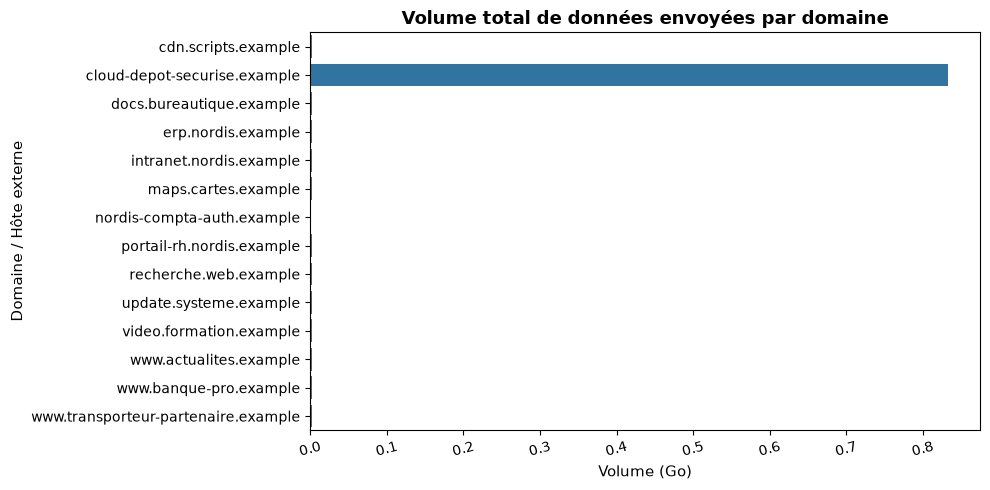

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

# Exemple : Visualiser le volume total exfiltré par hôte cible (serveur d'exfiltration)
if "proxy" in data:
    exfil_summary = data['proxy'].groupby("host")["octets_envoyes"].sum().reset_index()
    exfil_summary["Go_envoyes"] = exfil_summary["octets_envoyes"] / (1024 * 1024 * 1024)
    
    sns.barplot(data=exfil_summary, y="host", x="Go_envoyes")
    plt.title("Volume total de données envoyées par domaine", fontsize=13, fontweight="bold")
    plt.ylabel("Domaine / Hôte externe", fontsize=11)
    plt.xlabel("Volume (Go)", fontsize=11)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

In [35]:
serveurs_exfils = traffic_suspect['host'].unique().tolist()
debut_exfill, fin_exfill = traffic_suspect['horodatage'].min(), traffic_suspect['horodatage'].max()
print(f"Adresse des serveurs de rebond: {serveurs_exfils}")
print(f"Periode d'upload: {debut_exfill} à {fin_exfill}")

Adresse des serveurs de rebond: ['cloud-depot-securise.example']
Periode d'upload: 2026-09-19 01:37:00+00:00 à 2026-09-19 02:04:48+00:00


Le journal du proxy nous révèle plusieurs lignes d'upload depuis la machine PC-SIE-1000 associée au login l.perrin, vers l'adresse "cloud-depot-securise.example", sur la période du 19 septembre 2026, de 1h37 à 2h04

In [36]:
masque_upload = (traffic_suspect['methode'] == 'POST') & (traffic_suspect['statut'] == 200)
octets_exfils = traffic_suspect[masque_upload]['octets_envoyes'].sum()
paquet_Mo_moy = traffic_suspect[masque_upload]['octets_envoyes'].mean()  / (1024 * 1024)

mo_exfils = octets_exfils / (1024 * 1024)
go_exfils = octets_exfils / (1024 * 1024 * 1024)

print(f"Volume exfiltré : {octets_exfils} Octets")
print(f"=> Volume exfiltré en Mo : {mo_exfils:.2f} Mo")
print(f"=> Volume exfiltré en Go : {go_exfils:.2f} Go")

print(f"Volume paquet moyen : {paquet_Mo_moy:.2f} Mo")

Volume exfiltré : 894393390 Octets
=> Volume exfiltré en Mo : 852.96 Mo
=> Volume exfiltré en Go : 0.83 Go
Volume paquet moyen : 6.09 Mo


La volumétrie des données volées est estimée à 0,83 Go

In [37]:
masque_alertes_exfil = data['edr']['statut'] == 'ouvert'
data['edr'][masque_alertes_exfil]

,id,horodatage,machine,login,titre,gravite,statut,note_analyste
118,EDR-10203,2026-09-11 09:20:00+00:00,PC-SIE-1000,l.perrin,Page d'hameçonnage visitée,moyenne,ouvert,Connexion à un domaine récemment enregistré im...
146,EDR-10204,2026-09-14 00:57:00+00:00,SRV-FILE01,svc_monitoring,Création de compte à privilèges hors procédure,critique,ouvert,Compte svc_monitoring ajouté aux Admins du dom...
188,EDR-10205,2026-09-19 02:14:00+00:00,PC-SIE-1000,l.perrin,Exfiltration de données probable,critique,ouvert,Transfert sortant volumineux vers un hébergeur...
201,EDR-10206,2026-09-20 01:59:00+00:00,SRV-FILE01,svc_monitoring,Suppression de sauvegardes,critique,ouvert,Arrêt du service de sauvegarde puis suppressio...
202,EDR-10207,2026-09-20 03:25:00+00:00,SRV-FILE01,svc_monitoring,Comportement de rançongiciel,critique,ouvert,Chiffrement massif de fichiers sur les partage...


Il existait bien des alertes EDR qui avertissaient d'un transfert sortant volumineux depuis le PC-SIE-1000 le 19 septembre 2026. Les logs EDR nous confirment que la machine SRV-FILE01 est bien compromise d'après les logs du 20 septembre 2026, incluant des signalements et des chiffrements massifs de données. Ces alertes sont restées ouvertes jusqu'ici, démontrant qu'elles n'ont pas été prises en compte à temps ou que les contre-mesures n'ont pas encore été déployées

In [38]:
print(f"Nombre total d'alertes EDR : {data['edr']['horodatage'].count()}")
masque_edr_fp = data['edr']['statut'] == 'clos_faux_positif'
edr_fp = data['edr'][masque_edr_fp]
print(f"Nombre de faux positifs : {edr_fp['horodatage'].count()}")
edr_fp.head(10)


Nombre total d'alertes EDR : 208
Nombre de faux positifs : 203


,id,horodatage,machine,login,titre,gravite,statut,note_analyste
0,EDR-10001,2026-08-31 07:26:36+00:00,PC-LYO-1128,s.boyer,Connexion à un service cloud,info,clos_faux_positif,Sauvegarde personnelle
1,EDR-10002,2026-08-31 08:00:01+00:00,PC-SIE-1016,s.vincent,Script PowerShell,faible,clos_faux_positif,Tâche de maintenance planifiée
2,EDR-10004,2026-08-31 08:34:20+00:00,PC-SIE-1087,g.martin,Connexion à un service cloud,info,clos_faux_positif,Sauvegarde personnelle
3,EDR-10006,2026-08-31 10:24:06+00:00,PC-LIL-1030,n.simon,Outil d'administration détecté,faible,clos_faux_positif,PsExec utilisé par l'IT
4,EDR-10000,2026-08-31 11:42:07+00:00,PC-SIE-1027,g.dubois,Outil d'administration détecté,faible,clos_faux_positif,PsExec utilisé par l'IT
5,EDR-10003,2026-08-31 13:13:11+00:00,PC-LYO-1043,e.dubois,Fichier compressé volumineux,faible,clos_faux_positif,Export comptable mensuel
6,EDR-10005,2026-08-31 14:43:01+00:00,PC-LYO-1275,h.andre,Connexion à un service cloud,info,clos_faux_positif,Sauvegarde personnelle
7,EDR-10008,2026-09-01 07:48:23+00:00,PC-SIE-1276,n.garnier,Connexion à un service cloud,info,clos_faux_positif,Sauvegarde personnelle
8,EDR-10015,2026-09-01 07:49:35+00:00,PC-SIE-1217,k.lefebvre,Script PowerShell,faible,clos_faux_positif,Tâche de maintenance planifiée
9,EDR-10013,2026-09-01 10:01:28+00:00,PC-SIE-1000,l.perrin,Fichier compressé volumineux,faible,clos_faux_positif,Export comptable mensuel


In [39]:
repartition_edr = (
    data['edr']
    .groupby(['titre', 'note_analyste', 'statut'])
    .size()
    .reset_index(name='nombre')
)

repartition_edr

,titre,note_analyste,statut,nombre
0,Comportement de rançongiciel,Chiffrement massif de fichiers sur les partage...,ouvert,1
1,Connexion à un service cloud,Sauvegarde personnelle,clos_faux_positif,53
2,Création de compte à privilèges hors procédure,Compte svc_monitoring ajouté aux Admins du dom...,ouvert,1
3,Exfiltration de données probable,Transfert sortant volumineux vers un hébergeur...,ouvert,1
4,Fichier compressé volumineux,Export comptable mensuel,clos_faux_positif,53
5,Outil d'administration détecté,PsExec utilisé par l'IT,clos_faux_positif,53
6,Page d'hameçonnage visitée,Connexion à un domaine récemment enregistré im...,ouvert,1
7,Script PowerShell,Tâche de maintenance planifiée,clos_faux_positif,44
8,Suppression de sauvegardes,Arrêt du service de sauvegarde puis suppressio...,ouvert,1


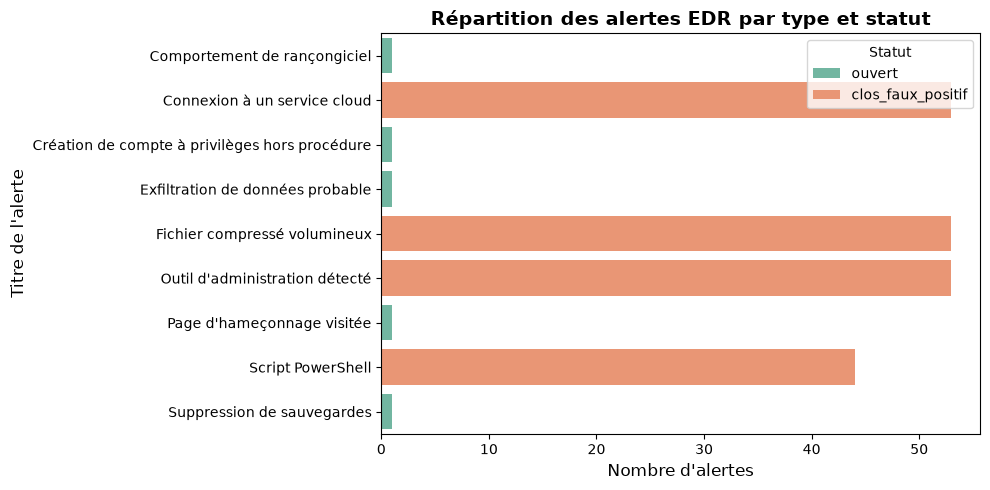

In [40]:
plt.figure(figsize=(10, 5))

# Comptage par titre et statut
edr_counts = data["edr"].groupby(["titre", "statut"]).size().reset_index(name="nombre")

# Tracé du diagramme en barres
sns.barplot(data=edr_counts, x="nombre", y="titre", hue="statut", palette="Set2")
plt.title("Répartition des alertes EDR par type et statut", fontsize=14, fontweight="bold")
plt.xlabel("Nombre d'alertes", fontsize=12)
plt.ylabel("Titre de l'alerte", fontsize=12)
plt.legend(title="Statut")
plt.tight_layout()
plt.show()

On voit que presque la totalité des alertes concerne des événements récurrents et banalisés : "Connexion à un service cloud", "Fichier compressé volumineux", "Outil d'administration détecté" et "Script PowerShell", correspondant respectivement aux tâches "Sauvegarde personnelle", "Export comptable mensuel", "PsExec utilisé par l'IT" et "Tâche de maintenance planifiée" selon les notes des analystes. Elles représentent donc 203 alertes sur les 208 au total.

#### <a id="synthese-niveau4"><h3>Synthèse Niveau 4</h3></a>
Selon les logs du pare-feu, sur la période du **13, 14, 15, 18, 19 et 20 septembre 2026**, on observe des activités ciblées et répétées de balayage sur les serveurs **SRV-FILE01**, **SRV-FILE02** et **SRV-BACKUP01**, de la part de la machine suspecte non répertoriée (**10.10.200.41**). Sur cette même période, on a constaté :

- __le 19 septembre 2026 à partir de 1h37__, le journal du pare-feu signale l'envoi partitionné de 0,83 Go de données vers un site externe (cloud-depot-securise.example), depuis le poste PC-SIE-1000 ;

- __le 20 septembre 2026__, le journal EDR indique la suppression et le chiffrement massif de données sur la machine SRV-FILE01.

Ces incidents avaient pourtant été mentionnés dans les logs EDR, mais n'ont pas été pris en compte à temps. Cela pourrait s'expliquer partiellement par l'asphyxie (ou la submersion) des notifications, entraînant une fatigue et une mécanisation de la résolution des alertes sans analyse en profondeur. De plus, des tâches pourtant banalisées, récurrentes, planifiées et même mensuelles continuent de déclencher des alertes EDR (« Export comptable mensuel », « Tâche de maintenance planifiée », etc.). Il y a donc un souci de paramétrage (ou de périmétrage) de l'EDR.

### <a id="niveau5"><h2>Niveau 5 — Conclusion et Recommandations de sécurité</h2></a>


```md
Établissez la chronologie complète de l’attaque et la liste des indicateurs de compromission.
Proposez des règles de détection qui auraient permis de repérer l’attaque plus tôt, et des mesures correctives.
```

#### <a id="chronologie-de-lattaque"><h3>Chronologie de l'attaque</h3></a>

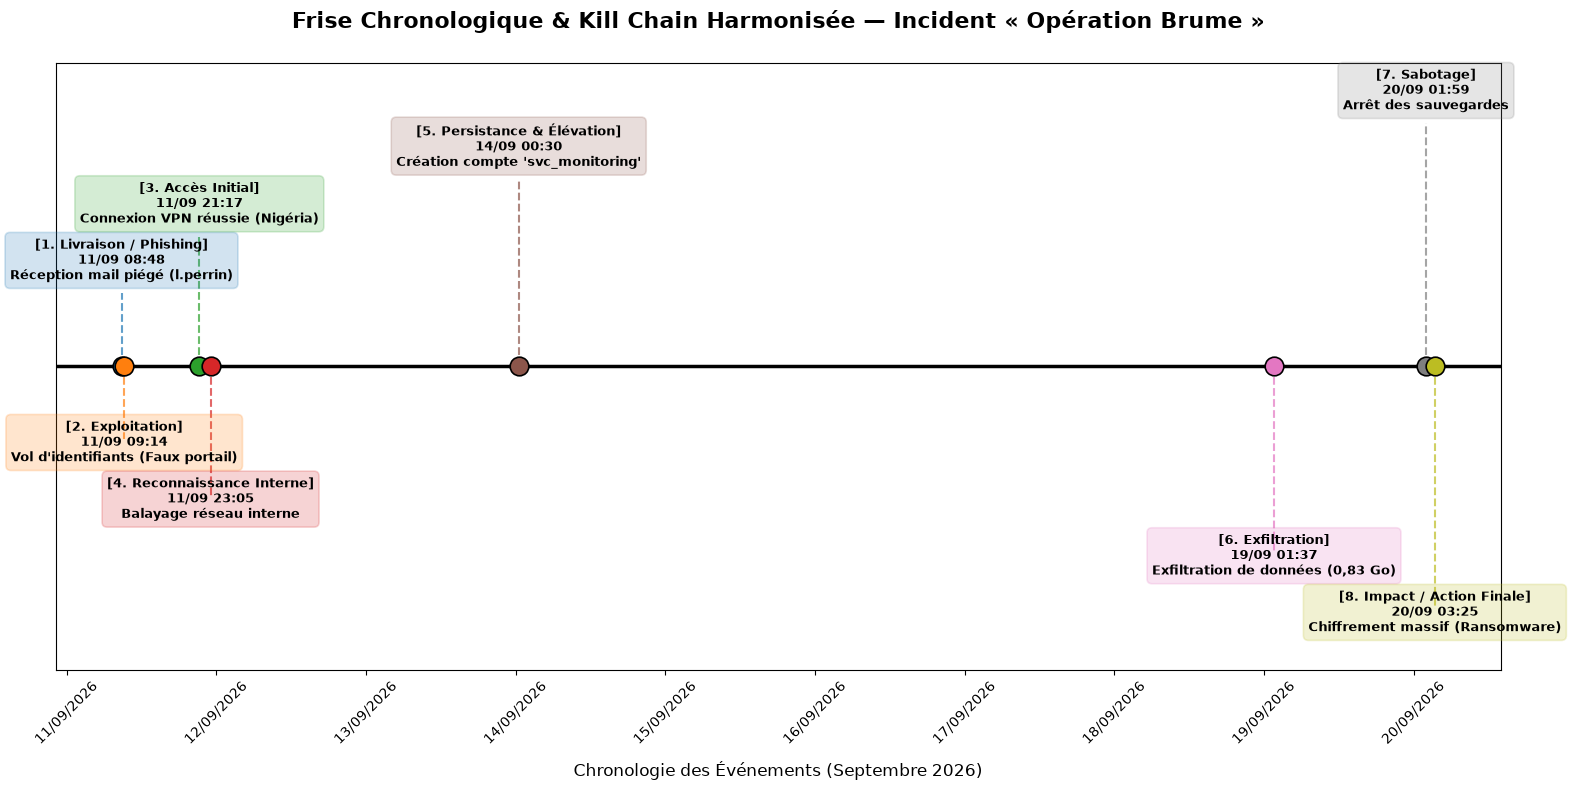

In [41]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Données de la chronologie harmonisées avec la Kill Chain
events = [
    {"date": "2026-09-11 08:48", "label": "Réception mail piégé (l.perrin)", "cat": "1. Livraison / Phishing"},
    {"date": "2026-09-11 09:14", "label": "Vol d'identifiants (Faux portail)", "cat": "2. Exploitation"},
    {"date": "2026-09-11 21:17", "label": "Connexion VPN réussie (Nigéria)", "cat": "3. Accès Initial"},
    {"date": "2026-09-11 23:05", "label": "Balayage réseau interne", "cat": "4. Reconnaissance Interne"},
    {"date": "2026-09-14 00:30", "label": "Création compte 'svc_monitoring'", "cat": "5. Persistance & Élévation"},
    {"date": "2026-09-19 01:37", "label": "Exfiltration de données (0,83 Go)", "cat": "6. Exfiltration"},
    {"date": "2026-09-20 01:59", "label": "Arrêt des sauvegardes", "cat": "7. Sabotage"},
    {"date": "2026-09-20 03:25", "label": "Chiffrement massif (Ransomware)", "cat": "8. Impact / Action Finale"}
]

df_events = pd.DataFrame(events)
df_events["date"] = pd.to_datetime(df_events["date"])

# Attribution des couleurs par phase d'attaque
categories = df_events["cat"].unique()
cmap = plt.get_cmap("tab10")
cat_to_color = {cat: cmap(i / len(categories)) for i, cat in enumerate(categories)}

fig, ax = plt.subplots(figsize=(16, 8))

# Niveaux en Y alternés pour éviter les superpositions d'étiquettes
y_levels = [1.8, -1.8, 3.2, -3.2, 4.6, -4.6, 6.0, -6.0]

for idx, row in df_events.iterrows():
    y = y_levels[idx % len(y_levels)]
    color = cat_to_color[row["cat"]]
    
    # Point marquant l'événement exact sur l'axe central
    ax.scatter(row["date"], 0, s=180, color=color, zorder=3, edgecolors="black", linewidths=1.2)
    
    # Ligne verticale reliant le point à l'étiquette
    ax.vlines(x=row["date"], ymin=0, ymax=y, color=color, linestyle="--", alpha=0.7, linewidth=1.5)
    
    # Boîte de texte claire et structurée
    ax.text(row["date"], y + (0.35 if y > 0 else -0.55), 
            f"[{row['cat']}]\n{row['date'].strftime('%d/%m %H:%M')}\n{row['label']}", 
            horizontalalignment='center', 
            fontsize=9, 
            fontweight='bold',
            bbox=dict(boxstyle="round,pad=0.4", fc=color, alpha=0.2, ec=color, linewidth=1.2))

# Ligne horizontale principale de la frise
ax.axhline(0, color="black", linewidth=2.5, zorder=1)

# Formatage de l'axe des dates
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m/%Y'))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
plt.xticks(rotation=45, fontsize=10)

# Nettoyage de l'axe Y et configuration des limites
ax.set_yticks([])
ax.set_ylim(-7.5, 7.5)

# Titres et habillage
ax.set_title("Frise Chronologique & Kill Chain Harmonisée — Incident « Opération Brume »", fontsize=16, fontweight="bold", pad=25)
ax.set_xlabel("Chronologie des Événements (Septembre 2026)", fontsize=12, labelpad=10)

plt.tight_layout()
plt.show()

| Phase de la Kill Chain | Date & Heure | Événement Clé & Acteurs Impliqués | Description Technique Détaillée |
| :--- | :--- | :--- | :--- |
| **1. Livraison / Phishing** | **11/09/2026 à 08:48** | Courriel malveillant reçu par `l.perrin` | Envoi d'un e-mail frauduleux de phishing depuis `comptabilite@fourniseur-x.example` avec le sujet « Facture impayée », contenant une pièce jointe suspecte (`facture_relance.pdf.htm`) et un lien vers un faux portail. |
| **2. Exploitation** | **11/09/2026 à 09:14** | Saisie des identifiants (Faux portail) | La victime `l.perrin` clique sur le lien et saisit ses identifiants professionnels sur le faux portail d'authentification (`nordis-compta-auth.example`). |
| **3. Accès Initial** | **11/09/2026 à 21:17** | Connexion VPN réussie (IP : `203.0.113.87`) | L'attaquant utilise les identifiants volés de `l.perrin` pour s'authentifier avec succès sur le VPN de l'entreprise depuis une adresse IP externe située au Nigéria. |
| **4. Reconnaissance Interne** | **11/09/2026 à 23:05** | Balayage réseau (Machine `10.10.200.41`) | Une machine interne non répertoriée (`10.10.200.41`) effectue un balayage des ports sensibles (SSH `22`, LDAP `389`, SMB `445`, MSSQL `1433`, RDP `3389`) pour cartographier le réseau. |
| **5. Persistance & Élévation** | **14/09/2026 à 00:30** | Création du compte `svc_monitoring` | Usurpation d'un compte informatique légitime (`n.vincent`) pour créer un compte technique de persistance (`svc_monitoring`) et l'élever au rang d'administrateur du domaine. |
| **6. Exfiltration** | **19/09/2026 à 01:37** | Exfiltration de données (~0,83 Go) | Transfert massif des données dérobées vers une plateforme cloud externe non autorisée (`cloud-depot-securise.example`) via des requêtes HTTP POST fragmentées en morceaux (`chunks`). |
| **7. Sabotage (Défense Evasion)** | **20/09/2026 à 01:59** | Arrêt et suppression des sauvegardes | Ciblage du serveur de sauvegarde (`SRV-BACKUP01`) pour désactiver les services de backup et entraver toute capacité de restauration rapide. |
| **8. Impact / Action Finale** | **20/09/2026 à 03:25** | Chiffrement massif (Ransomware) | Tentative de déploiement et d'activation du ransomware sur les serveurs de fichiers (`SRV-FILE01` et `SRV-FILE02`) pour paralyser l'infrastructure de l'entreprise. |

#### <a id="indicateurs-de-compromission"><h3>Indicateurs de compromission</h3></a>

| Indicateurs de compromission (IoC) | Type / Attribut | Description / Contexte dans le projet | Source associée |
| :--- | :--- | :--- | :--- |
| `203.0.113.87` | Adresse IP source / Attaquant | Adresse IP externe utilisée pour les connexions VPN suspectes (Brésil, Chine, Nigeria, Russie) et l'accès administrateur/création de comptes. | `vpn_auth.csv`, `ad_events.jsonl`, `firewall.csv` |
| `l.perrin` | Nom d'utilisateur (Login) | Compte du service comptabilité compromis initialement via une campagne de phishing. | `vpn_auth.csv`, `proxy_web.csv`, `mail_gateway.csv`, `edr_alerts.json` |
| `comptabilite@fourniseur-x.example` | Adresse e-mail (Expéditeur) | Expéditeur du courriel de phishing piégé (« Facture impayée - régularisation urgente »). | `mail_gateway.csv` |
| `l.perrin@nordis.example` | Adresse e-mail (Destinataire) | Destinataire du courriel de phishing initial. | `mail_gateway.csv` |
| `facture_relance.pdf.htm` | Nom de fichier / Pièce jointe | Fichier joint malveillant à double extension envoyé lors du phishing. | `mail_gateway.csv` |
| `https://nordis-compta-auth.example/connexion` | URL / Lien malveillant | Lien d'hameçonnage inclus dans le courriel de phishing pour collecter les identifiants. | `mail_gateway.csv`, `proxy_web.csv` |
| `nordis-compta-auth.example` | Nom de domaine (Host) | Faux portail d'authentification visité par la victime lors du phishing. | `proxy_web.csv` |
| `10.10.200.41` | Adresse IP interne / Machine suspecte | Machine non répertoriée dans l'inventaire effectuant le balayage des ports (scanning) des serveurs. | `firewall.csv`, `inventaire_parc.csv` |
| `n.vincent` | Nom d'utilisateur (Login) | Compte privilégié du service informatique compromis, ayant servi à créer le compte de persistance. | `ad_events.jsonl` |
| `svc_monitoring` | Nom d'utilisateur (Compte créé) | Compte de service créé frauduleusement et ajouté au groupe des administrateurs du domaine. | `ad_events.jsonl`, `edr_alerts.json` |
| `Admins du domaine` | Groupe Active Directory | Groupe de sécurité sensible auquel a été ajouté le compte `svc_monitoring`. | `ad_events.jsonl` |
| `cloud-depot-securise.example` | Nom de domaine / Hébergeur | Serveur distant externe utilisé pour l'exfiltration massive des données de l'entreprise. | `proxy_web.csv` |
| `PC-SIE-1000` | Nom de poste (Hostname) | Poste de travail du siège associé à la victime `l.perrin`, point de départ du phishing et de l'exfiltration. | `proxy_web.csv`, `inventaire_parc.csv`, `edr_alerts.json` |
| `SRV-FILE01` | Nom de serveur (Hostname) | Serveur de fichiers ciblé, compromis, et ayant subi le chiffrement massif (ransomware). | `firewall.csv`, `inventaire_parc.csv`, `edr_alerts.json` |
| `SRV-FILE02` | Nom de serveur (Hostname) | Serveur de fichiers cible secondaire atteint par l'attaquant. | `firewall.csv`, `inventaire_parc.csv` |
| `SRV-BACKUP01` | Nom de serveur (Hostname) | Serveur de sauvegarde ciblé lors des connexions RDP suspectes. | `firewall.csv`, `inventaire_parc.csv` |

#### <a id="regles-de-detection"><h3>Règles de détection</h3></a>

| Catégorie de Menace | Règle de Détection Comportementale | Critères de Déclenchement & Logique | Seuil (Threshold) & Fenêtre Temporelle | Actions de Tuning (Réduction des Faux Positifs) |
| :--- | :--- | :--- | :--- | :--- |
| **Identité & Accès** | **Authentification Anormale (Impossible Travel / VPN atypique)** | Session réussie depuis une localisation géographique incohérente avec l'historique ou via un fournisseur d'anonymisation / VPN commercial non autorisé. | **Seuil :** $\ge 1$ événement réussi depuis une source inédite pour l'utilisateur dans une fenêtre de **5 minutes**. | Exclure les plages IP des filiales, les déplacements professionnels déclarés et le VPN d'entreprise légitime. |
| **Persistance** | **Création et Élévation Rapide de Privilèges** | Création d'un compte utilisateur suivie à bref délai de son intégration dans un groupe à hauts privilèges (ex: Admins du domaine). | **Seuil :** $\ge 1$ compte créé et promu par un utilisateur non membre des équipes IAM/Sécurité en moins de **15 minutes**. | Exclure les comptes de service techniques standard associés à des processus d'automatisation validés (ITSM). |
| **Réseau / C2** | **Trafic vers des Domaines Récents ou Suspects** | Requête DNS ou flux HTTP/HTTPS vers un domaine externe à très faible réputation ou dont la date d'enregistrement est très récente. | **Seuil :** $\ge 1$ requête vers un domaine enregistré depuis **moins de 30 jours** ou classé malveillant par la réputation globale. | Mettre sur liste blanche les nouveaux domaines validés par l'équipe de sécurité ou les outils de filtrage de contenu. |
| **Endpoint / Exécution** | **Utilisation de Fichiers à Double Extension** | Création, téléchargement ou exécution d'un fichier dont le nom utilise une extension trompeuse masquant un script ou un exécutable. | **Seuil :** $\ge 1$ occurrence détectée par l'EDR ou la passerelle de messagerie (ex: `.pdf.exe`, `.docx.scr`, `.pdf.htm`). | Exclure les outils de développement internes ou les kits de tests autorisés et documentés. |
| **Mouvement Latéral** | **Balayage de Ports et Reconnaissance Interne** | Une machine source interne initie des connexions vers de multiples hôtes distincts sur des ports réseau sensibles ou d'administration. | **Seuil :** Connexion vers **$> 5$ hôtes distincts** sur des ports sensibles (SSH, RDP, SMB, LDAP) en moins de **10 minutes**. | Exclure les outils de supervision, d'inventaire ou les scanners de vulnérabilités légitimes identifiés par leur IP source. |

#### <a id="mesures-correctives">Mesures correctives</a>

| Phase de Remédiation | Action / Mesure Corrective | Cibles / Éléments Concernés | Objectif de la Mesure |
| :--- | :--- | :--- | :--- |
| **1. Confinement d'urgence** | **Isolation réseau des machines compromises** | Serveurs de fichiers (`SRV-FILE01`, `SRV-FILE02`) et machine suspecte (`10.10.200.41`) | Empêcher la propagation latérale du ransomware et stopper l'accès aux partages réseau. |
| **1. Confinement d'urgence** | **Blocage des flux et des IoC réseau** | IP attacker (`203.0.113.87`), Domaines (`nordis-compta-auth.example`, `cloud-depot-securise.example`) | Couper immédiatement les canaux de commande et de contrôle (C2) et l'exfiltration de données. |
| **2. Éradication** | **Révocation des sessions et réinitialisation des mots de passe** | Compte victime (`l.perrin`) et compte IT compromis (`n.vincent`) | Mettre fin aux accès actifs de l'attaquant via les identifiants volés. |
| **2. Éradication** | **Suppression des comptes de persistance et audit AD** | Compte `svc_monitoring` et groupes d'administrateurs du domaine | Nettoyer les portes dérobées créées par l'attaquant et vérifier l'absence d'autres comptes suspects. |
| **3. Restauration** | **Restauration des systèmes et données** | `SRV-FILE01`, `SRV-FILE02` et vérification préalable de `SRV-BACKUP01` | Assurer le retour à la normale à partir de sauvegardes saines, vérifiées et non corrompues. |
| **4. Renforcement & Post-Incident** | **Déploiement du MFA et revue des accès** | Ensemble des accès distants (VPN) et comptes à privilèges | Sécuriser l'authentification pour contrer l'efficacité des futures campagnes de phishing. |
| **4. Renforcement & Post-Incident** | **Sensibilisation ciblée à la cybersécurité** | Service comptabilité (`l.perrin` et ses collègues) | Former les équipes à repérer les techniques de social engineering (ex: faux e-mails de facturation, double extension). |

### <a id="outils"><h2>**Outils & Lien**</h2></a>

In [42]:
# Exporter les dépendances
%pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.


lien github: [https://github.com/AaronRandrianarisona/projet_analyse_incident_securite](https://github.com/AaronRandrianarisona/projet_analyse_incident_securite)